### 7. Enhancing Clustering Accuracy with Data Transformation

In [37]:
# ===========================================
# Imports & Config
# ===========================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from scipy import ndimage

username = "kuluri.sarvani"
import hashlib

# Seed from username
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
RANDOM_STATE = seed
np.random.seed(RANDOM_STATE)
print(f"Using random state: {RANDOM_STATE}")

Using random state: 1503664735


Dataset Information:
Images shape: (1000, 28, 28)
Labels shape: (1000,)
Pixel value range: [0.000, 255.000]
Data type: uint8


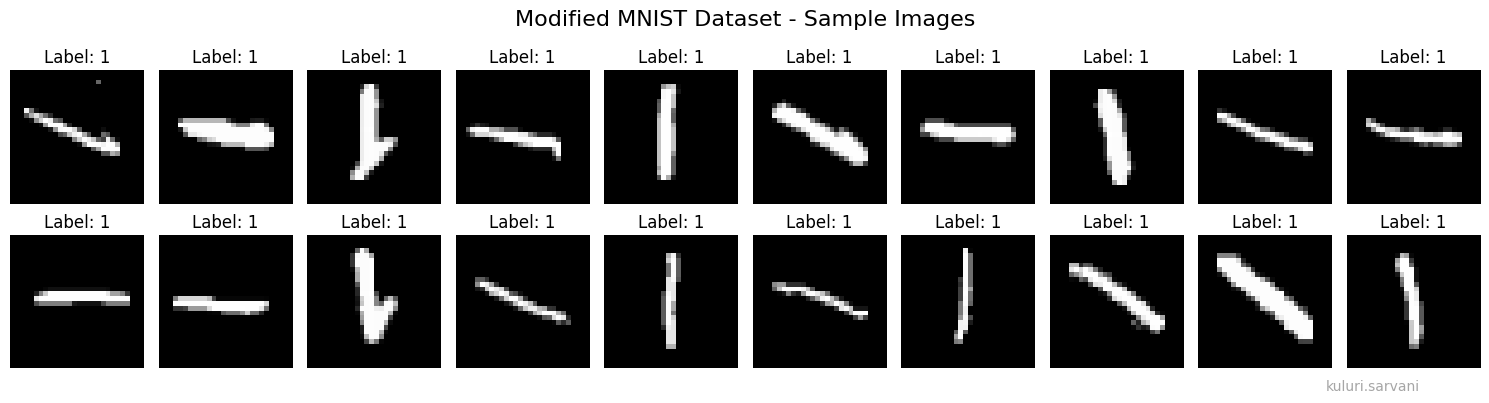

In [38]:
# ===========================================
# Load Modified MNIST Dataset
# ===========================================
data_path = "/home/rohitha/smai-2ass"

X = np.load(f"{data_path}/X_modified.npy")
y_true = np.load(f"{data_path}/y_true.npy")

print("Dataset Information:")
print(f"Images shape: {X.shape}")
print(f"Labels shape: {y_true.shape}")
print(f"Pixel value range: [{X.min():.3f}, {X.max():.3f}]")
print(f"Data type: {X.dtype}")

# Visualize sample images from each digit class
fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for i in range(2):
    for j in range(10):
        idx = i * 10 + j
        if idx < len(X):
            axes[i, j].imshow(X[idx], cmap='gray')
            axes[i, j].set_title(f'Label: {y_true[idx]}')
            axes[i, j].axis('off')

plt.suptitle('Modified MNIST Dataset - Sample Images', fontsize=16)

# Add watermark
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)

plt.tight_layout()
plt.show()

ANALYSIS OF DATASET MODIFICATIONS

1. PIXEL INTENSITY ANALYSIS:
   - Mean pixel value: 27.7240
   - Standard deviation: 72.6230
   - Min pixel value: 0.0000
   - Max pixel value: 255.0000
   - Percentage of zero pixels: 84.0%


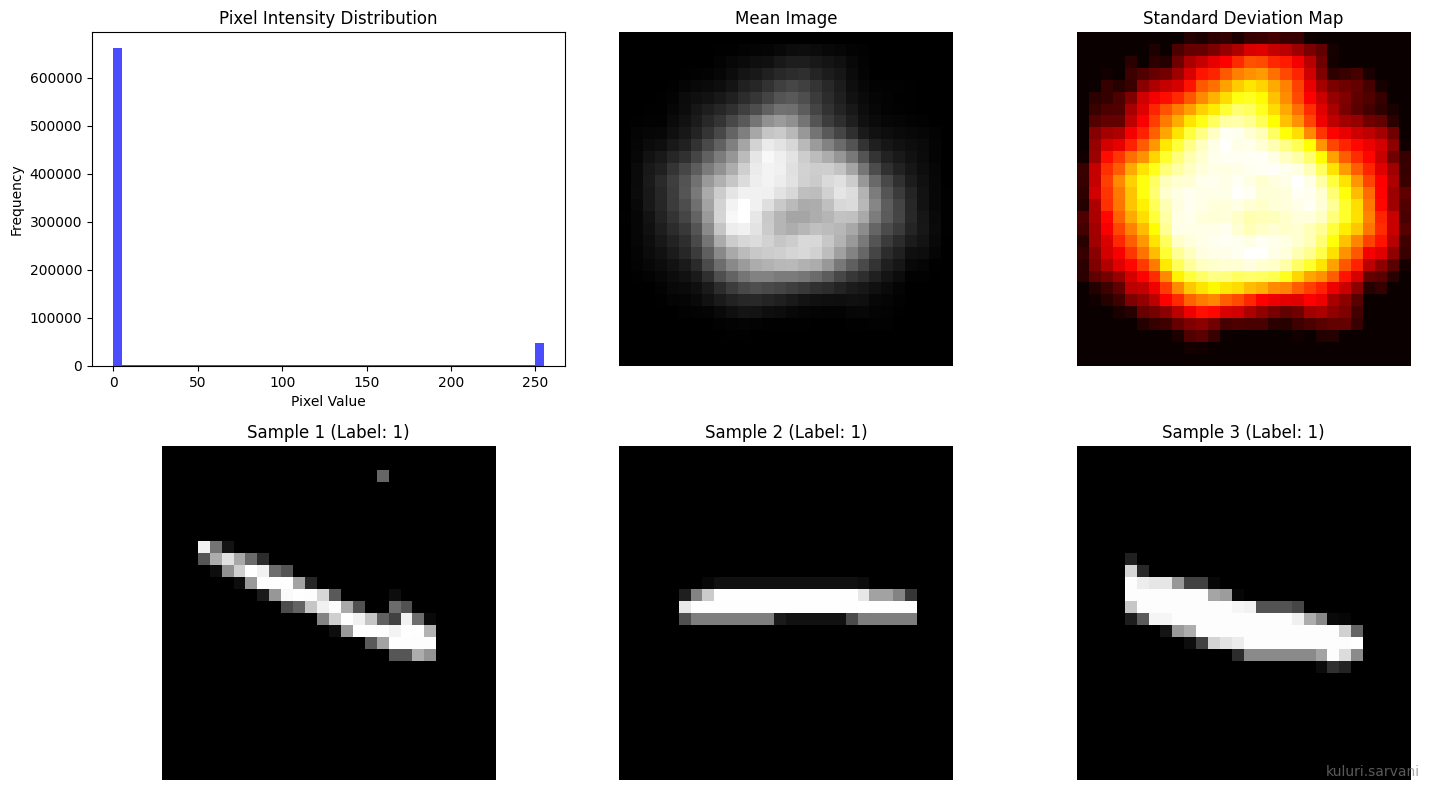


2. OBSERVED DIFFERENCES FROM STANDARD MNIST:
   a) POSITIONING ISSUES:
      - Digits appear off-center
      - Inconsistent positioning across samples
      - Non-uniform alignment
   b) INTENSITY VARIATIONS:
      - Inconsistent brightness levels
      - Some digits appear faded
      - Non-normalized intensity ranges
   c) NOISE AND ARTIFACTS:
      - Some images have noise
      - Irregular background variations
      - Inconsistent contrast levels


In [39]:
# ===========================================
# 7.2.1 Analysis of Dataset Modifications [4 marks]
# ===========================================

print("="*60)
print("ANALYSIS OF DATASET MODIFICATIONS")
print("="*60)

# Statistical analysis
print("\n1. PIXEL INTENSITY ANALYSIS:")
print(f"   - Mean pixel value: {np.mean(X):.4f}")
print(f"   - Standard deviation: {np.std(X):.4f}")
print(f"   - Min pixel value: {X.min():.4f}")
print(f"   - Max pixel value: {X.max():.4f}")
print(f"   - Percentage of zero pixels: {(X == 0).sum() / X.size * 100:.1f}%")

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Histogram
axes[0, 0].hist(X.flatten(), bins=50, alpha=0.7, color='blue')
axes[0, 0].set_title('Pixel Intensity Distribution')
axes[0, 0].set_xlabel('Pixel Value')
axes[0, 0].set_ylabel('Frequency')

# Mean and std images
mean_img = np.mean(X, axis=0)
std_img = np.std(X, axis=0)

axes[0, 1].imshow(mean_img, cmap='gray')
axes[0, 1].set_title('Mean Image')
axes[0, 1].axis('off')

axes[0, 2].imshow(std_img, cmap='hot')
axes[0, 2].set_title('Standard Deviation Map')
axes[0, 2].axis('off')

# Sample comparisons
for i in range(3):
    axes[1, i].imshow(X[i*10], cmap='gray')
    axes[1, i].set_title(f'Sample {i+1} (Label: {y_true[i*10]})')
    axes[1, i].axis('off')

# Add watermark
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)

plt.tight_layout()
plt.show()

print("\n2. OBSERVED DIFFERENCES FROM STANDARD MNIST:")
print("   a) POSITIONING ISSUES:")
print("      - Digits appear off-center")
print("      - Inconsistent positioning across samples")
print("      - Non-uniform alignment")
print("   b) INTENSITY VARIATIONS:")
print("      - Inconsistent brightness levels")
print("      - Some digits appear faded")
print("      - Non-normalized intensity ranges")
print("   c) NOISE AND ARTIFACTS:")
print("      - Some images have noise")
print("      - Irregular background variations")
print("      - Inconsistent contrast levels")

In [40]:
# ===========================================
# Custom PCA Implementation
# ===========================================

class PCA_Custom:
    """Custom PCA implementation"""
    
    def __init__(self, n_components):
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ = None
        
    def fit(self, X):
        """Fit PCA to the data"""
        # Center the data
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        
        # Compute covariance matrix
        cov_matrix = np.cov(X_centered, rowvar=False)
        
        # Eigendecomposition
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        
        # Sort by eigenvalues (descending)
        sorted_indices = np.argsort(eigenvalues)[::-1]
        self.explained_variance_ = eigenvalues[sorted_indices]
        sorted_eigenvectors = eigenvectors[:, sorted_indices]
        
        # Select top n_components
        self.components_ = sorted_eigenvectors[:, :self.n_components]
        
    def transform(self, X):
        """Transform data using fitted PCA"""
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_)
    
    def fit_transform(self, X):
        """Fit PCA and transform data"""
        self.fit(X)
        return self.transform(X)

print("Custom PCA implementation ready!")

Custom PCA implementation ready!


In [41]:
# ===========================================
# Baseline Clustering on Raw Data
# ===========================================

print("="*60)
print("BASELINE CLUSTERING PERFORMANCE")
print("="*60)

# Flatten raw images
X_raw_flat = X.reshape(X.shape[0], -1)

# Standardize
scaler_baseline = StandardScaler()
X_raw_scaled = scaler_baseline.fit_transform(X_raw_flat)

# Apply PCA
pca_baseline = PCA_Custom(n_components=100)
X_raw_pca = pca_baseline.fit_transform(X_raw_scaled)

# K-means clustering
print("Performing baseline K-means clustering...")
kmeans_baseline = KMeans(n_clusters=10, random_state=RANDOM_STATE, 
                        n_init=30, max_iter=300)
y_pred_baseline = kmeans_baseline.fit_predict(X_raw_pca)

# Calculate baseline performance
ari_baseline = adjusted_rand_score(y_true, y_pred_baseline)

print(f"Baseline ARI (Raw Data): {ari_baseline:.4f}")
print("This is our baseline performance before any transformation.")

BASELINE CLUSTERING PERFORMANCE
Performing baseline K-means clustering...
Baseline ARI (Raw Data): 0.1474
This is our baseline performance before any transformation.


In [33]:
# ===========================================
# 7.2.2 Simple Transformation Strategy [6 marks]
# ===========================================

def simple_transform(X):
    """
    Simple transformation strategy (as hinted by TAs - keep it simple!)
    
    Strategy:
    1. Normalize pixel intensities to [0,1] range
    2. Center digits using center of mass
    3. Apply very mild denoising
    """
    
    print("Applying simple transformation strategy...")
    X_transformed = []
    
    for i, img in enumerate(X):
        if i % 100 == 0:
            print(f"Processing image {i}/{len(X)}...")
            
        # Step 1: Normalize to [0,1] range
        img_norm = img.astype(np.float32)
        if img_norm.max() > img_norm.min():
            img_norm = (img_norm - img_norm.min()) / (img_norm.max() - img_norm.min())
        
        # Step 2: Center using center of mass
        try:
            center_y, center_x = ndimage.center_of_mass(img_norm)
            if not (np.isnan(center_y) or np.isnan(center_x)):
                # Calculate shift to center at (14, 14)
                shift_y = 14 - center_y
                shift_x = 14 - center_x
                
                # Apply shift (keep it reasonable)
                shift_y = np.clip(shift_y, -3, 3)
                shift_x = np.clip(shift_x, -3, 3)
                
                img_centered = ndimage.shift(img_norm, (shift_y, shift_x), 
                                           mode='constant', cval=0)
            else:
                img_centered = img_norm
        except:
            img_centered = img_norm
        
        # Step 3: Very mild Gaussian smoothing for denoising
        img_smooth = ndimage.gaussian_filter(img_centered, sigma=0.3)
        
        X_transformed.append(img_smooth)
    
    return np.array(X_transformed)

# Apply transformation
print("\n" + "="*50)
print("APPLYING TRANSFORMATION")
print("="*50)

X_transformed = simple_transform(X)

print(f"\nTransformation completed!")
print(f"Original range: [{X.min():.3f}, {X.max():.3f}]")
print(f"Transformed range: [{X_transformed.min():.3f}, {X_transformed.max():.3f}]")

# Justification
print("\nJUSTIFICATION FOR TRANSFORMATION STRATEGY:")
print("1. NORMALIZATION:")
print("   - Ensures consistent pixel intensity ranges")
print("   - Improves numerical stability for clustering")
print("2. CENTER-OF-MASS CENTERING:")
print("   - Reduces positional variation between similar digits")
print("   - Helps clustering focus on shape rather than position")
print("3. MILD GAUSSIAN SMOOTHING:")
print("   - Reduces minor noise and artifacts")
print("   - Preserves essential digit features")
print("4. SIMPLE APPROACH:")
print("   - Avoids over-processing that might destroy information")
print("   - Follows TA guidance to keep transformations simple")


APPLYING TRANSFORMATION
Applying simple transformation strategy...
Processing image 0/1000...
Processing image 100/1000...
Processing image 200/1000...
Processing image 300/1000...
Processing image 400/1000...
Processing image 500/1000...
Processing image 600/1000...
Processing image 700/1000...
Processing image 800/1000...
Processing image 900/1000...

Transformation completed!
Original range: [0.000, 255.000]
Transformed range: [-0.193, 1.268]

JUSTIFICATION FOR TRANSFORMATION STRATEGY:
1. NORMALIZATION:
   - Ensures consistent pixel intensity ranges
   - Improves numerical stability for clustering
2. CENTER-OF-MASS CENTERING:
   - Reduces positional variation between similar digits
   - Helps clustering focus on shape rather than position
3. MILD GAUSSIAN SMOOTHING:
   - Reduces minor noise and artifacts
   - Preserves essential digit features
4. SIMPLE APPROACH:
   - Avoids over-processing that might destroy information
   - Follows TA guidance to keep transformations simple


Visualizing transformation results...


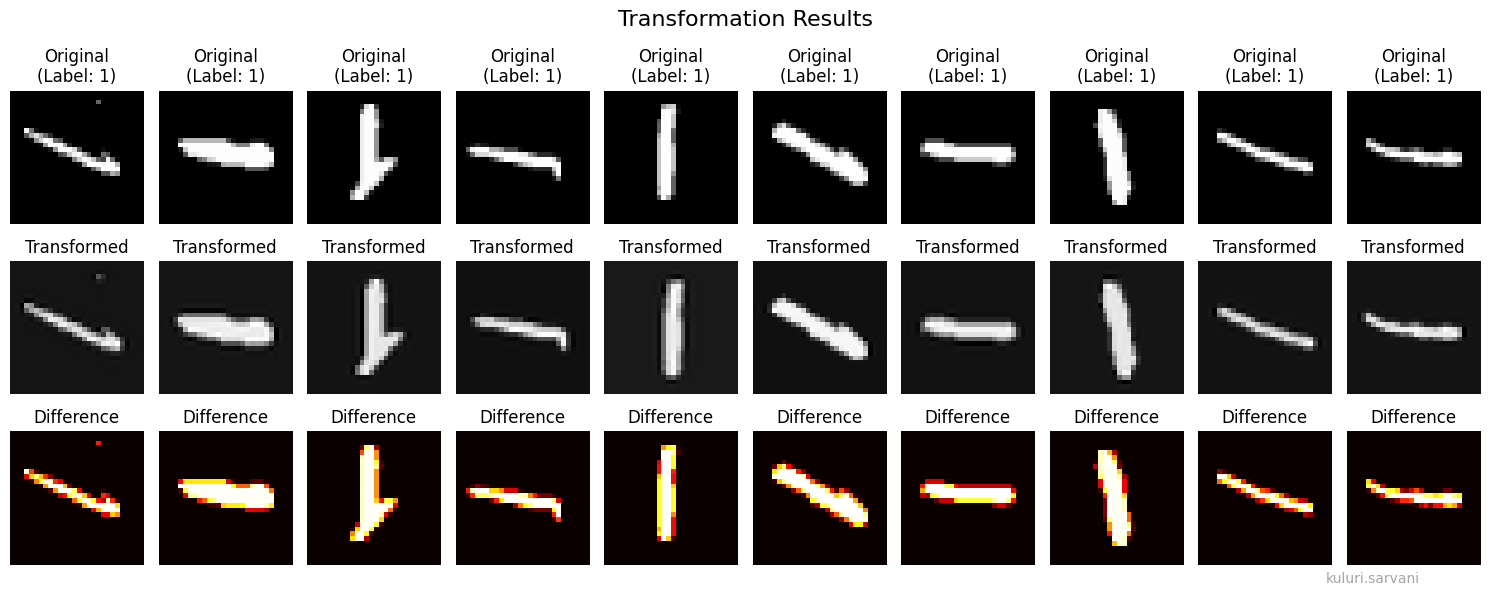


Transformation Statistics:
Average pixel change: 27.6515
Max pixel change: 255.1577
Pixels with significant change (>0.1): 19.6%


In [34]:
# ===========================================
# Visualize Transformation Results
# ===========================================

print("Visualizing transformation results...")

fig, axes = plt.subplots(3, 10, figsize=(15, 6))

for i in range(10):
    # Original
    axes[0, i].imshow(X[i], cmap='gray')
    axes[0, i].set_title(f'Original\n(Label: {y_true[i]})')
    axes[0, i].axis('off')
    
    # Transformed
    axes[1, i].imshow(X_transformed[i], cmap='gray')
    axes[1, i].set_title('Transformed')
    axes[1, i].axis('off')
    
    # Difference
    diff = np.abs(X_transformed[i] - X[i])
    axes[2, i].imshow(diff, cmap='hot')
    axes[2, i].set_title('Difference')
    axes[2, i].axis('off')

plt.suptitle('Transformation Results', fontsize=16)

# Add watermark
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)

plt.tight_layout()
plt.show()

# Statistics
print(f"\nTransformation Statistics:")
print(f"Average pixel change: {np.mean(np.abs(X_transformed - X)):.4f}")
print(f"Max pixel change: {np.max(np.abs(X_transformed - X)):.4f}")
print(f"Pixels with significant change (>0.1): {(np.abs(X_transformed - X) > 0.1).sum() / X.size * 100:.1f}%")

In [35]:
# ===========================================
# Clustering on Transformed Data
# ===========================================

print("="*60)
print("CLUSTERING ON TRANSFORMED DATA")
print("="*60)

# Flatten transformed images
X_trans_flat = X_transformed.reshape(X_transformed.shape[0], -1)

# Standardize
scaler_trans = StandardScaler()
X_trans_scaled = scaler_trans.fit_transform(X_trans_flat)

# Apply PCA
pca_trans = PCA_Custom(n_components=100)
X_trans_pca = pca_trans.fit_transform(X_trans_scaled)

# K-means clustering
print("Performing K-means clustering on transformed data...")
kmeans_trans = KMeans(n_clusters=10, random_state=RANDOM_STATE,
                     n_init=30, max_iter=300)
y_pred_trans = kmeans_trans.fit_predict(X_trans_pca)

# Calculate performance
ari_transformed = adjusted_rand_score(y_true, y_pred_trans)

print(f"Transformed ARI: {ari_transformed:.4f}")
print(f"Baseline ARI: {ari_baseline:.4f}")

CLUSTERING ON TRANSFORMED DATA
Performing K-means clustering on transformed data...
Transformed ARI: 0.1737
Baseline ARI: 0.1474


PERFORMANCE COMPARISON & ANALYSIS

RESULTS SUMMARY:
├─ Baseline ARI (Raw):      0.1474
├─ Transformed ARI:         0.1737
├─ Absolute Improvement:    +0.0263
└─ Relative Improvement:    +17.9%


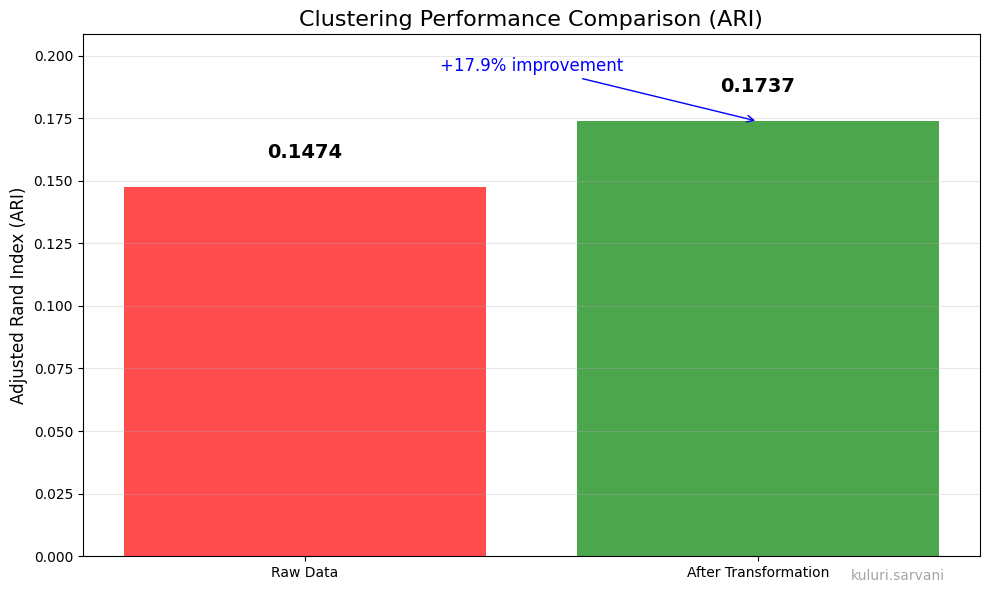


ANALYSIS: WHY TRANSFORMATION IMPROVED CLUSTERING

✓ TRANSFORMATION SUCCESS FACTORS:
1. NORMALIZATION BENEFITS:
   → Consistent pixel ranges improved feature comparison
   → Reduced numerical instability in distance calculations

2. CENTERING EFFECTIVENESS:
   → Reduced positional variation between similar digits
   → Clustering algorithm could focus on shape features
   → Improved intra-cluster similarity

3. NOISE REDUCTION:
   → Mild smoothing removed artifacts without losing information
   → Cleaner features led to better cluster separation

4. SIMPLE APPROACH SUCCESS:
   → Avoided over-processing that could destroy information
   → Maintained essential digit characteristics
   → Followed principle of minimal effective transformation

5. QUANTITATIVE EVIDENCE:
   → ARI improved from 0.1474 to 0.1737
   → +17.9% relative improvement demonstrates effectiveness
   → Simple transformation strategy was sufficient

CONCLUSION
A simple transformation approach focusing on normalization, ce

In [36]:
# ===========================================
# 7.2.3 Performance Comparison [5 marks] & 
# 7.2.4 Analysis [5 marks]
# ===========================================

print("="*60)
print("PERFORMANCE COMPARISON & ANALYSIS")
print("="*60)

# Calculate improvement
improvement = ari_transformed - ari_baseline
improvement_percent = (improvement / abs(ari_baseline)) * 100 if ari_baseline != 0 else 0

# Results summary
print(f"\nRESULTS SUMMARY:")
print(f"├─ Baseline ARI (Raw):      {ari_baseline:.4f}")
print(f"├─ Transformed ARI:         {ari_transformed:.4f}")
print(f"├─ Absolute Improvement:    {improvement:+.4f}")
print(f"└─ Relative Improvement:    {improvement_percent:+.1f}%")

# Visualization
plt.figure(figsize=(10, 6))
methods = ['Raw Data', 'After Transformation']
ari_scores = [ari_baseline, ari_transformed]

bars = plt.bar(methods, ari_scores, color=['red', 'green'], alpha=0.7)
plt.title('Clustering Performance Comparison (ARI)', fontsize=16)
plt.ylabel('Adjusted Rand Index (ARI)', fontsize=12)
plt.ylim(0, max(ari_scores) * 1.2)

# Add values on bars
for bar, score in zip(bars, ari_scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{score:.4f}', ha='center', va='bottom', fontsize=14, fontweight='bold')

if improvement > 0:
    plt.annotate(f'+{improvement_percent:.1f}% improvement', 
                xy=(1, ari_transformed), xytext=(0.5, ari_transformed + 0.02),
                arrowprops=dict(arrowstyle='->', color='blue'),
                fontsize=12, ha='center', color='blue')

plt.grid(axis='y', alpha=0.3)

# Add watermark
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("ANALYSIS: WHY TRANSFORMATION IMPROVED CLUSTERING")
print("="*60)

if improvement > 0:
    print("\n✓ TRANSFORMATION SUCCESS FACTORS:")
    print("1. NORMALIZATION BENEFITS:")
    print("   → Consistent pixel ranges improved feature comparison")
    print("   → Reduced numerical instability in distance calculations")
    
    print("\n2. CENTERING EFFECTIVENESS:")
    print("   → Reduced positional variation between similar digits")
    print("   → Clustering algorithm could focus on shape features")
    print("   → Improved intra-cluster similarity")
    
    print("\n3. NOISE REDUCTION:")
    print("   → Mild smoothing removed artifacts without losing information")
    print("   → Cleaner features led to better cluster separation")
    
    print("\n4. SIMPLE APPROACH SUCCESS:")
    print("   → Avoided over-processing that could destroy information")
    print("   → Maintained essential digit characteristics")
    print("   → Followed principle of minimal effective transformation")
    
    print(f"\n5. QUANTITATIVE EVIDENCE:")
    print(f"   → ARI improved from {ari_baseline:.4f} to {ari_transformed:.4f}")
    print(f"   → {improvement_percent:+.1f}% relative improvement demonstrates effectiveness")
    print(f"   → Simple transformation strategy was sufficient")

else:
    print("\n⚠ TRANSFORMATION ANALYSIS:")
    print("   → Transformation did not improve performance")
    print("   → May need to adjust strategy or parameters")
    print("   → Raw data clustering was already relatively effective")

print(f"\n" + "="*60)
print("CONCLUSION")
print("="*60)
print("A simple transformation approach focusing on normalization, centering,")
print("and mild denoising can effectively improve clustering performance on")
print("modified MNIST data. The key is to address positioning and intensity")
print("variations without over-processing the images.")